<center><h1>

#**Análisis Descriptivo de Datos**

**Elaborado por: Duvan Steven Garcia Ramos**

**Universidad de Cundinamarca**

**Especialización en Analítica y Ciencia de Datos**

**CAD2092023205 - Business Analytics (BA)**

**Docente: Edgar Mauricio López Rojas**

</h1></center>


---


En este cuaderno se desarrolla un análisis descriptivo de datos aplicado al caso de estudio TecnoAndes, una tienda de tecnología con sedes en varias ciudades de Colombia.
El objetivo es explorar, limpiar y organizar la información disponible en tres fuentes de datos (ventas, clientes e inventario), calcular estadísticas descriptivas y generar visualizaciones que permitan interpretar el comportamiento de la empresa.

##**1. Importación de librerias**
El primer paso consiste en importar las librerías necesarias para el análisis. Cada una cumple un rol específico dentro del flujo de trabajo, en este caso se utilizan las siguientes:

* `google.colab (files)`: Permite subir y descargar archivos desde el entorno de Google Colab, facilitando la interacción con los datasets.
* `IPython.display (Markdown y display)`: Se utiliza para mostrar texto con formato enriquecido (Markdown) dentro del notebook, mejorando la presentación de resultados.
* `pandas`: Librería fundamental para la manipulación y análisis de datos en estructuras tipo DataFrame.
* `os`: Permite interactuar con el sistema operativo, por ejemplo para manejar rutas y archivos.
* `unicodedata`: Util para normalizar y limpiar textos, especialmente cuando se requiere estandarizar caracteres especiales o acentos.
* `matplotlib.pyplot:` Es un módulo de la librería Matplotlib que permite crear gráficos en 2D de manera sencilla. Con pyplot se pueden generar distintos tipos de visualizaciones como líneas, barras, dispersión y más. Además, ofrece funciones para personalizar títulos, etiquetas y estilos de los gráficos.
* `seaborn:` Es una librería construida sobre Matplotlib que facilita la creación de gráficos estadísticos con un diseño más atractivo y moderno. Seaborn simplifica la construcción de gráficos como barplots, lineplots, boxplots y heatmaps, integrándose directamente con estructuras de datos de pandas.

In [124]:
# Importar librerias
from google.colab import files
from IPython.display import Markdown, display
import pandas as pd
import os
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns


##**2. Carga y exploración de datos**
En esta sección se realiza la gestión inicial de los siguientes archivos los cuales contienen la información del caso de estudio TecnoAndes:

* **ventas.csv:** Contiene 515 transacciones realizadas en el año 2025.
* **clientes.json:** Incluye información de 15 clientes registrados en el CRM.
* **productos.xlsx:** Catálogo de 10 productos disponibles en el inventario.

Inicialmente se realiza:

* **Eliminación de archivos previos en la sesión:** Se verifica si los archivos ya existen en el entorno de Colab. En caso afirmativo, se eliminan para garantizar que se trabajará con la versión más reciente de los datasets.
* **Carga de archivos desde el equipo local:** Se utiliza la función files.upload() para seleccionar y subir los archivos directamente desde el computador. Esto permite disponer de los datasets en el entorno de análisis sin necesidad de rutas externas.

Nota: subir todos los archivos al mismo tiempo.

In [125]:
# Borrar archivos anteriores si ya existen en la sesión para evitar duplicados
for archivo in ['ventas.csv','clientes.json','productos.xlsx']:
    if os.path.exists(archivo):
        os.remove(archivo)

# Buscar archivos desde el PC
uploaded = files.upload()

Saving ventas.csv to ventas.csv
Saving productos.xlsx to productos.xlsx
Saving clientes.json to clientes.json


### **2.1 Creación de DataFrames y exploración inicial**

En esta etapa se asignan los nombres de los archivos a variables y se convierten en DataFrames de pandas, lo que permite manipularlos como tablas dentro del entorno de Colab. Posteriormente se realiza una exploración básica para conocer sus dimensiones y estructuras.

In [126]:
# Asignar nombres de archivos a variables
archivo_ventas = 'ventas.csv'
archivo_clientes = 'clientes.json'
archivo_productos = 'productos.xlsx'

# Crear DataFrame por archivo
df_ventas = pd.read_csv(archivo_ventas, sep=';', encoding="utf-8")
df_clientes = pd.read_json(archivo_clientes)
df_productos = pd.read_excel(archivo_productos, sheet_name="catalogo")

# Visualizar dimensiones de los DataFrames
texto_dimensiones = "###Dimensiones iniciales de DataFrames:\n"
for nombre, df in [("Ventas", df_ventas), ("Clientes", df_clientes), ("Productos", df_productos)]:
    texto_dimensiones += f"* {nombre}: {df.shape[0]} filas, {df.shape[1]} columnas\n"
display(Markdown(texto_dimensiones))

# Mostrar las primeras filas de los DataFrame
display(Markdown("###Primeras filas de DataFrames:"))
for nombre, df in [("Ventas", df_ventas), ("Clientes", df_clientes), ("Productos", df_productos)]:
    display(Markdown(f"* {nombre}:"))
    display(df.head())
    display(Markdown("<br>"))

###Dimensiones iniciales de DataFrames:
* Ventas: 515 filas, 7 columnas
* Clientes: 15 filas, 5 columnas
* Productos: 10 filas, 4 columnas


###Primeras filas de DataFrames:

* Ventas:

,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal
0,490,2025-05-20,7,P003,2.0,15%,Web
1,430,2025/03/27,1,P004,1.0,10%,Web
2,83,2025-12-06,14,P003,1.0,NaN,web
3,121,2025/12/19,13,P005,3.0,15%,App
4,222,2025/07/29,2,P006,-3.0,0%,Tienda


<br>

...

,id_cliente,nombre,email,ciudad,fecha_registro
0,1,Ana Gómez,ana1@correo.com,bogota,2024-01-24
1,2,Luis Pérez,luis2@correo.com,Cali,2024-04-08
2,3,María Rodríguez,maría3@correo.com,Medellín,2024-12-04
3,4,Carlos López,None,Bogotá,2024-02-19
4,5,LAURA MARTÍNEZ,laura5@correo.com,Bucaramanga,2024-01-01


<br>

* Productos:

,id_producto,nombre,categoria,precio_unitario
0,P001,Portátil,Computo,3200000
1,P002,Mouse,Accesorios,45000
2,P003,Teclado,accesorios,120000
3,P004,"Monitor 24""",Computo,780000
4,P005,Audífonos,Audio,150000


<br>

### **2.2 Perfilado de DataFrames**

En este paso se genera un informe general de cada DataFrame, útil para evaluar la calidad y estructura de los datos:

* **Número de filas y duplicados:** Indica el tamaño del dataset y si existen registros repetidos que podrían afectar el análisis.
* **Tipo de dato por columna:** Identifica si las variables están correctamente tipadas (numéricas, texto, fechas).
* **Valores nulos y porcentaje:** Permite identificar columnas con información incompleta y estimar el impacto en el análisis.
* **Valores únicos:** Revela la diversidad de cada variable, útil para detectar categorías o posibles claves.
* **Ejemplo de valores:** Se visualizan los valores de la primera fila como referencia.

In [127]:
# Explorar informacion general de DataFrames
def perfilar(df, nombre):
    display(Markdown(f"* {nombre}<br> Total filas: {len(df)}<br> Total filas duplicadas: {df.duplicated().sum()}"))
    df_info_general = pd.DataFrame({
        "Tipo_Dato": df.dtypes.astype(str),
        "Nulos": df.isna().sum(),
        "%_Nulos": (df.isna().mean() * 100).round(1),
        "Unicos": df.nunique(),
        "Ejemplo": df.iloc[0],
    })
    display(df_info_general)
    display(Markdown("<br>"))

display(Markdown("###Información general de DataFrames:"))
perfilar(df_ventas, "Ventas")
perfilar(df_clientes, "Clientes")
perfilar(df_productos, "Productos")



###Información general de DataFrames:

* Ventas<br> Total filas: 515<br> Total filas duplicadas: 15

,Tipo_Dato,Nulos,%_Nulos,Unicos,Ejemplo
id_venta,int64,0,0.0,500,490
fecha,object,0,0.0,408,2025-05-20
id_cliente,int64,0,0.0,16,7
id_producto,object,0,0.0,10,P003
cantidad,float64,9,1.7,10,2.0
descuento,object,135,26.2,4,15%
canal,object,0,0.0,5,Web


<br>

* Clientes<br> Total filas: 15<br> Total filas duplicadas: 0

,Tipo_Dato,Nulos,%_Nulos,Unicos,Ejemplo
id_cliente,int64,0,0.0,15,1
nombre,object,0,0.0,15,Ana Gómez
email,object,2,13.3,13,ana1@correo.com
ciudad,object,0,0.0,8,bogota
fecha_registro,object,0,0.0,14,2024-01-24


<br>

* Productos<br> Total filas: 10<br> Total filas duplicadas: 0

,Tipo_Dato,Nulos,%_Nulos,Unicos,Ejemplo
id_producto,object,0,0.0,10,P001
nombre,object,0,0.0,10,Portátil
categoria,object,0,0.0,8,Computo
precio_unitario,int64,0,0.0,10,3200000


<br>

### **2.3 Exploración de valores y validaciones**

En este paso se revisan columnas clave y posibles inconsistencias en los datos:

* **Valores categóricos:** Se listan las categorías únicas y su distribución de las siguientes columnas para detectar variaciones de escritura o categorías poco frecuentes:
  - canal y descuento del archivo de ventas.
  - ciudad del archivo de clientes.
  - categoria de archivo de productos.

* **Cantidades negativas en ventas:** Se contabilizan registros con valores menores a cero en la columna 'cantidades' del archivo de ventas, debido a que podrían ser errores.

* **Formato de fechas:** Se visualiza una muestra aleatoria de la columna fecha del archivo de ventas para verificar su estructura y consistencia.

In [128]:
# Identificar Valores distintos en las columnas de texto y su distribucion
# Lista centralizada: (DataFrame, columna, nombre_archivo)
configuraciones = [
    (df_ventas, "canal", "Ventas"),
    (df_ventas, "descuento", "Ventas"),
    (df_clientes, "ciudad", "Clientes"),
    (df_productos, "categoria", "Productos")
]

for df, col, nom in configuraciones:
    display(Markdown(f"* ### Valores en la columna '{col}' del archivo de {nom}:"))
    print(sorted(df[col].dropna().unique()))
    display(df[col].value_counts().sort_index())

# Identificar cantidades negativas en ventas
display(Markdown(f"* ### Cantidades negativas en Ventas:"))
print((df_ventas['cantidad'] < 0).sum())

# Identificar formatos de fecha
display(Markdown(f"* ### Muestra de fecha en Ventas:"))
print(df_ventas['fecha'].sample(10, random_state=0).tolist())

* ### Valores en la columna 'canal' del archivo de Ventas:

['App', 'TIENDA', 'Tienda', 'Web', 'web']


,count
canal,
App,107
TIENDA,110
Tienda,105
Web,105
web,88


* ### Valores en la columna 'descuento' del archivo de Ventas:

['0%', '10%', '15%', '5%']


...

,count
categoria,
Accesorios,1
Accesorios,1
Almacenamiento,1
Audio,1
Computo,3
Oficina,1
Redes,1
accesorios,1


* ### Cantidades negativas en Ventas:

13


* ### Muestra de fecha en Ventas:

['2025/03/20', '2025-04-09', '2025/09/27', '29/05/2025', '2025/03/08', '22/07/2025', '24/07/2025', '13/03/2025', '2025/04/27', '15/03/2025']


### **2.4 Hallazgos principales de la exploración**

Tras la revisión inicial del contenido de los archivos se identificaron los siguientes problemas en los datos:

    | N | Problema                                             | Archivo   |
    |---|------------------------------------------------------|-----------|
    | 1 | Filas duplicadas                                     | ventas    |
    | 2 | Fechas en 3 formatos distintos                       | ventas    |
    | 3 | Cantidades nulas y negativas                         | ventas    |
    | 4 | Descuento como texto ("10%", "")                     | ventas    |
    | 5 | Canal con mayúsculas inconsistentes                  | ventas    |
    | 6 | Ventas de un cliente inexistente (id 16)             | ventas    |
    | 7 | Ciudades con tildes, espacios y mayúsculas mezcladas | clientes  |
    | 8 | Nombres en MAYÚSCULAS, emails nulos                  | clientes  |
    | 9 | Categorías con espacios y mayúsculas                 | productos |

##**3. Limpieza y organización de la información**

Esta etapa de limpieza y organización de la información inicia con la preparación del entorno para aplicar transformaciones sobre los datos de la siguiente manera:

* **Creando copias de los DataFrames:** Se crean copias de los DataFrames(df_cp_ventas, df_cp_clientes, df_cp_productos) para realizar modificaciones sin alterar los originales.
* **Creando bitácora de calidad (log_calidad)** Se inicializa una lista que almacenará las acciones de limpieza realizadas, útil para auditoría y trazabilidad.
* **Creando función registrar:** la cual Permite documentar cada paso de limpieza indicando:
  - Nombre de la modificacion realizada.
  - Número de registros antes y después.
  - Cantidad de registros afectados.

In [129]:
# Generar copias de DataFrames para realizar modificaciones
df_cp_ventas = df_ventas.copy()
df_cp_clientes = df_clientes.copy()
df_cp_productos = df_productos.copy()

# Crear lista que funcionara como bitácora de las modificaciones realizadas
log_calidad = []

# Definir funcion que alimentara la bitacora.
def registrar(paso, antes, despues):
    log_calidad.append({"paso": paso, "antes": antes, "después": despues, "afectados": antes - despues})

### **3.1 Eliminación de duplicados en ventas**

En este paso se depura el DataFrame de ventas para garantizar que cada transacción aparezca una sola vez, para esto se realiza lo siguiente:

* Calcular el número de filas iniciales.
* Aplicar `drop_duplicates()` para eliminar registros repetidos.
* Registrar la acción en la bitácora (log_calidad) indicando el número de filas antes y después.
* Imprimir el resultado para validar la eliminación.

In [130]:
# Contar filas del DataFrame de ventas
antes = len(df_cp_ventas)

# Eliminar duplicados del DataFrame de ventas
df_cp_ventas = df_cp_ventas.drop_duplicates()

# Registrar la eliminacion de duplicados en la bitacora
registrar("Eliminar duplicados en ventas", antes, len(df_cp_ventas))

# Visualizar resultado
display(Markdown(f"### Eliminacion de duplicados en Ventas:"))
display(Markdown(f"* Total inicial de registros: {antes} filas"))
display(Markdown(f"* Total final de registros {len(df_cp_ventas)} filas"))

### Eliminacion de duplicados en Ventas:

* Total inicial de registros: 515 filas

* Total final de registros 500 filas

### **3.2 Normalización de fechas en ventas**

En este paso se estandariza la columna fecha del DataFrame de ventas siguiendo los siguientes pasos:

* **Crear función parsear_fecha:** La cual intenta convertir las fechas usando tres formatos comunes (%Y-%m-%d, %d/%m/%Y, %Y/%m/%d).
* **Asignar resultados:** Las fechas válidas se transforman a tipo datetime; las no reconocidas se marcan como NaT.
* **Validación:** Se contabilizan las fechas no reconocidas y se muestra el rango mínimo y máximo de fechas válidas.
* **Muestra aleatoria:** Se imprime una selección de 10 fechas para verificar la consistencia del formato.

In [131]:
# Definir funcion que convierte fechas
def parsear_fecha(serie):
    resultado = pd.Series(pd.NaT, index=serie.index)
    for fmt in ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]:
        faltan = resultado.isna()
        resultado[faltan] = pd.to_datetime(serie[faltan], format=fmt, errors="coerce")
    return resultado

# Llamar funcion para convertir valores de la columna fecha de ventas
df_cp_ventas["fecha"] = parsear_fecha(df_cp_ventas["fecha"])

# Visualizar resultado
display(Markdown(f"### Normalizacion de la columna 'fecha' de Ventas:"))
print("Fechas no reconocidas:", df_cp_ventas["fecha"].isna().sum())
print("Rango de fechas:", df_cp_ventas["fecha"].min().date(), "a", df_cp_ventas["fecha"].max().date())

# Identificar formatos de fecha
display(Markdown(f"### Muestra de 'fecha' en Ventas:"))
print(df_cp_ventas['fecha'].sample(10, random_state=0).dt.strftime("%Y-%m-%d").tolist())

### Normalizacion de la columna 'fecha' de Ventas:

Fechas no reconocidas: 0
Rango de fechas: 2025-01-03 a 2025-12-29


### Muestra de 'fecha' en Ventas:

['2025-07-22', '2025-07-14', '2025-11-29', '2025-10-22', '2025-12-07', '2025-03-13', '2025-01-27', '2025-01-09', '2025-07-25', '2025-03-07']


### **3.3 Tratamiento de cantidades nulas y negativas en ventas**

En este paso se depura la columna cantidad del DataFrame de ventas de la siguiente manera:

* **Identificación de registros inválidos:** Se seleccionan las filas con valores nulos o menores/iguales a cero.
* **Clasificación de motivos:** Se etiqueta cada rechazo como “cantidad nula” o “cantidad ≤ 0”.
* **Eliminación de registros:** Se eliminan las filas inválidas del DataFrame.
* **Conversión de tipo:** La columna cantidad se transforma a entero (int) para asegurar consistencia.
* **Registro en bitácora:** Se documenta el paso en log_calidad, indicando el número de filas antes y después.
* **Validación final:** Se muestra el conteo de motivos de rechazo.

In [132]:
# Contar filas del DataFrame de ventas antes de realizar el procesamiento
antes = len(df_cp_ventas)

# Clasificar el rechazo de la columna cantidad
rechazos = df_cp_ventas[df_cp_ventas["cantidad"].isna() | (df_cp_ventas["cantidad"] <= 0)].copy()
rechazos["motivo"] = rechazos["cantidad"].apply(lambda x: "cantidad nula" if pd.isna(x) else "cantidad <= 0")

# Eliminar registros rechazados
df_cp_ventas = df_cp_ventas.drop(rechazos.index)

# Cambiar el tipo de dato a int
df_cp_ventas["cantidad"] = df_cp_ventas["cantidad"].astype(int)

# Registrar el cambio en la bitacora
registrar("Cantidad nula o <= 0", antes, len(df_cp_ventas))

# Visualizar resultados
display(Markdown("###Conteo de registros rechazados:"))
display(rechazos["motivo"].value_counts())

###Conteo de registros rechazados:

,count
motivo,
cantidad <= 0,13
cantidad nula,9


### **3.4 Normalización de la columna descuento en ventas**

En este paso se transforma la columna descuento de ventas para asegurar consistencia en su interpretación, para ello se realizan los siguientes pasos:

* Se reemplazan por "0%" los valores nulos y vacíos.
* Se quita el carácter de porcentaje (%) para trabajar solo con números.
* Los valores se convierten a tipo float y se dividen entre 100, de modo que "10%" se transforma en 0.10.
* Se visualiza la distribución de descuentos ya normalizados.

In [133]:
# Procesar la columna descuento del archivo de ventas
df_cp_ventas["descuento"] = (
    df_cp_ventas["descuento"]
      .fillna("0%")
      .replace("", "0%")
      .str.rstrip("%")
      .astype(float) / 100
)

# Visualizar resultados
display(Markdown("###Valores de la columna 'descuento' del archivo de ventas:"))
df_cp_ventas["descuento"].value_counts().sort_index()

###Valores de la columna 'descuento' del archivo de ventas:

,count
descuento,
0.00,216
0.05,75
0.10,94
0.15,93


### **3.5 Normalización de variables categóricas**

En este paso se aplican transformaciones para homogenizar los valores de texto en los diferentes DataFrames:

* **Ventas**
  * Canal: Se eliminan espacios y se capitaliza para evitar inconsistencias en mayúsculas/minúsculas.

* **Clientes**
  * Ciudad: Se crea la función normalizar que convierte a minúsculas y se eliminan espacios y tildes. Luego se mapea con un diccionario (mapa_ciudades) para estandarizar nombres de ciudades.
  * Nombre: Se transforma a formato título (str.title()), corrigiendo nombres escritos en mayúsculas.
  * Email: Se reemplazan valores nulos por un correo genérico "sin_email@desconocido.com".
  * Fecha de registro: Se convierte a tipo datetime para análisis temporal.

* **Productos**
  * Categoría: Se eliminan espacios y se capitaliza la primera letra para uniformidad.
* **Validación:** Se imprimen los valores únicos de ciudades, categorías y canales para confirmar la estandarización.

In [134]:
# Normalizar canal de ventas
df_cp_ventas["canal"] = df_cp_ventas["canal"].str.strip().str.capitalize()

# Crear funcion para normalizar la ciudad de clientes
def normalizar(texto):
    """Minúsculas, sin espacios extremos y sin tildes."""
    texto = str(texto).strip().lower()
    return "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")

# Crear mapa de normalizacion para ciudades
mapa_ciudades = {
    "bogota": "Bogotá", "medellin": "Medellín", "cali": "Cali", "barranquilla": "Barranquilla",
    "bucaramanga": "Bucaramanga", "cartagena": "Cartagena", "pereira": "Pereira",
}

# Procesar variables categoricas de clientes
df_cp_clientes["ciudad"] = df_cp_clientes["ciudad"].map(normalizar).map(mapa_ciudades)
df_cp_clientes["nombre"] = df_cp_clientes["nombre"].str.title()
df_cp_clientes["email"] = df_cp_clientes["email"].fillna("sin_email@desconocido.com")
df_cp_clientes["fecha_registro"] = pd.to_datetime(df_cp_clientes["fecha_registro"])

# Normalizar categoria de productos
df_cp_productos["categoria"] = df_cp_productos["categoria"].str.strip().str.capitalize()

# Visualizar resultados
display(Markdown("###Valores de las variables categoricas:"))
print("Ciudades:", df_cp_clientes["ciudad"].unique())
print("Categorías:", df_cp_productos["categoria"].unique())
print("Canales:", df_cp_ventas["canal"].unique())

###Valores de las variables categoricas:

Ciudades: ['Bogotá' 'Cali' 'Medellín' 'Bucaramanga' 'Cartagena' 'Barranquilla']
Categorías: ['Computo' 'Accesorios' 'Audio' 'Oficina' 'Almacenamiento' 'Redes']
Canales: ['Web' 'App' 'Tienda']


### **3.6 Control de integridad entre tablas**

En este paso se valida que las ventas estén correctamente relacionadas con clientes y productos existentes:

* **Detección de clientes huérfanos:** Se realiza un merge entre ventas y clientes para identificar registros de ventas cuyo id_cliente no existe en la tabla de clientes. Los registros huérfanos se contabilizan y se listan sus identificadores.
* **Eliminación de ventas inválidas:** Se eliminan las filas correspondientes a clientes inexistentes. Se registran en la bitácora (log_calidad) bajo el motivo “cliente inexistente”.
* **Validación de productos:** Se verifica que todos los id_producto en ventas existan en la tabla de productos. En caso contrario, se lanza una excepción indicando la presencia de productos huérfanos.

In [135]:
# Realizar un left join entre ventas y clientes por id_cliente
chequeo = df_cp_ventas.merge(df_cp_clientes[["id_cliente"]], on="id_cliente", how="left", indicator=True)
huerfanas = chequeo[chequeo["_merge"] == "left_only"]
display(Markdown("###Ventas con cliente inexistente:"))
print(len(huerfanas),"Ventas")
display(Markdown("###Id del cliente inexistente:"))
print(huerfanas["id_cliente"].unique())

# Contar filas del DataFrame de ventas antes de realizar el procesamiento
antes = len(df_cp_ventas)

# Eliminar ventas con clientes inexistentes
h = df_cp_ventas[df_cp_ventas["id_cliente"].isin(huerfanas["id_cliente"])].assign(motivo="cliente inexistente")
rechazos = pd.concat([rechazos, h])
df_cp_ventas = df_cp_ventas.drop(h.index)

# Registrar el cambio en la bitacora
registrar("Cliente inexistente", antes, len(df_cp_ventas))

# Validar la existencia de id_productos de ventas en productos
assert df_cp_ventas["id_producto"].isin(df_cp_productos["id_producto"]).all(), "Existen productos huérfanos"

###Ventas con cliente inexistente:

23 Ventas


###Id del cliente inexistente:

[16]


### **3.7 Integración y enriquecimiento de la información**

En este paso se construye el DataFrame consolidado que servirá como base para el análisis:

* **Integración de tablas:** Se realiza un merge entre ventas, productos y clientes (con ciudad), asegurando que cada transacción tenga su información completa.
* **Cálculo de métricas económicas:**
  * Se calcula el subtotal multiplicando la cantidad por el precio unitario.
  * El Valor de descuento se halla multiplicando el subtotal por el porcentaje de descuento (redondeado).
  * Y por lo tanto el total es igual al subtotal menos el valor de descuento.

* **Variables temporales:** Año, mes y día de la semana se extraen de la fecha para facilitar análisis temporales.
* **Ordenamiento y limpieza final:** Por ultimo se ordenan las filas por fecha e id de venta y se reinicia el índice para mantener consistencia.

In [136]:
# Unir los dataframes de ventas, clientes y productos
df = (df_cp_ventas
      .merge(df_cp_productos, on="id_producto", how="inner")
      .merge(df_cp_clientes[["id_cliente", "ciudad"]], on="id_cliente", how="inner"))

# Realizar calculos de metricas economicas.
df["subtotal"] = df["cantidad"] * df["precio_unitario"]
df["valor_descuento"] = (df["subtotal"] * df["descuento"]).round(0)
df["total"] = df["subtotal"] - df["valor_descuento"]

# Descomponer fecha
df["año"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["dia_semana"] = df["fecha"].dt.day_name()

# Ordenar y reiniciar indice
df = df.sort_values(["fecha", "id_venta"]).reset_index(drop=True)

display(Markdown("###Tabla con los 3 archivos integrados:<br>"))
df.head()

###Tabla con los 3 archivos integrados:<br>

,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal,nombre,categoria,precio_unitario,ciudad,subtotal,valor_descuento,total,año,mes,dia_semana
0,241,2025-01-03,9,P004,1,0.05,App,"Monitor 24""",Computo,780000,Bogotá,780000,39000.0,741000.0,2025,1,Friday
1,419,2025-01-03,9,P002,2,0.15,Web,Mouse,Accesorios,45000,Bogotá,90000,13500.0,76500.0,2025,1,Friday
2,398,2025-01-04,13,P006,4,0.00,Tienda,Impresora,Oficina,650000,Medellín,2600000,0.0,2600000.0,2025,1,Saturday
3,156,2025-01-05,2,P010,5,0.00,Tienda,Router WiFi,Redes,210000,Cali,1050000,0.0,1050000.0,2025,1,Sunday
4,452,2025-01-05,14,P003,3,0.00,Web,Teclado,Accesorios,120000,Barranquilla,360000,0.0,360000.0,2025,1,Sunday


### **3.8 Validación de reglas de calidad**

En este paso se definen y verifican reglas de integridad sobre el DataFrame consolidado:

* **Reglas aplicadas**
  * id_venta único → cada venta debe tener un identificador único.
  * sin fechas nulas → todas las transacciones deben tener fecha válida.
  * cantidad > 0 → las cantidades deben ser estrictamente positivas.
  * descuento entre 0 y 1 → los descuentos deben estar expresados como proporciones válidas.
  * total <= subtotal → el total nunca puede superar el subtotal.
  * todas las ciudades mapeadas → cada cliente debe tener ciudad estandarizada.
  * fechas dentro de 2025 → todas las ventas corresponden al año 2025.

* **Validación automática**
  * Se imprime el resultado de cada regla con ✅ o ❌.
  * Se utiliza assert para detener el flujo si alguna regla falla, obligando a revisar los datos antes de continuar.

In [137]:
# Listar reglas de validacion
reglas = {
    "id_venta único": df["id_venta"].is_unique,
    "sin fechas nulas": df["fecha"].notna().all(),
    "cantidad > 0": (df["cantidad"] > 0).all(),
    "descuento entre 0 y 1": df["descuento"].between(0, 1).all(),
    "total <= subtotal": (df["total"] <= df["subtotal"]).all(),
    "todas las ciudades mapeadas": df["ciudad"].notna().all(),
    "fechas dentro de 2025": (df["año"] == 2025).all(),
}

# Visualizar resultados
display(Markdown("###Validacion de reglas de calidad:"))
for regla, ok in reglas.items():
    print(("✅" if ok else "❌"), regla)
assert all(reglas.values()), "Falló una validación: los datos deben revisarse antes de cargar"

###Validacion de reglas de calidad:

✅ id_venta único
✅ sin fechas nulas
✅ cantidad > 0
✅ descuento entre 0 y 1
✅ total <= subtotal
✅ todas las ciudades mapeadas
✅ fechas dentro de 2025


### **3.9 Bitácora de calidad**

En este paso se muestra la bitácora (log_calidad) que contiene el historial de transformaciones aplicadas durante la limpieza:

Cada registro incluye:
  * Paso aplicado: el cual se refiere al nombre de la acción realizada.
  * Antes y después: número de filas antes y después de la operación.
  * Afectados: cantidad de registros modificados o eliminados.

La bitácora permite auditar el proceso y verificar la trazabilidad de cada decisión tomada.

In [138]:
# Visualizar bitácora de calidad
display(Markdown("###Bitacora de calidad:"))
pd.DataFrame(log_calidad)

###Bitacora de calidad:

,paso,antes,después,afectados
0,Eliminar duplicados en ventas,515,500,15
1,Cantidad nula o <= 0,500,478,22
2,Cliente inexistente,478,455,23


## **4. Cálculo de estadísticas descriptivas**

En esta etapa se generan estadísticas básicas que permiten comprender la distribución y comportamiento de las variables numéricas en cada DataFrame:

* **Medidas de tendencia central:** Media y mediana, que muestran el valor típico de las variables.
* **Medidas de dispersión:** Desviación estándar, valores mínimo y máximo, que indican la variabilidad de los datos.
* **Cuartiles (25%, 50%, 75%):** Permiten identificar la distribución y detectar posibles valores atípicos.

Se utiliza el método describe() de pandas, que resume automáticamente estas métricas para todas las columnas numéricas.

In [139]:
# Hallar estadisticas descriptivas del DataFrame integrado
display(Markdown("### Estadística descriptiva del DataFrame integrado:"))
display((df.describe().round(2)))

### Estadística descriptiva del DataFrame integrado:

,id_venta,fecha,id_cliente,cantidad,descuento,precio_unitario,subtotal,valor_descuento,total,año,mes
count,455.00,455,455.00,455.00,455.00,455.00,455.00,455.00,455.00,455.0,455.00
mean,251.43,2025-06-22 04:03:41.538461440,7.93,3.04,0.06,612296.70,1876549.45,114289.01,1762260.44,2025.0,6.20
min,1.00,2025-01-03 00:00:00,1.00,1.00,0.00,45000.00,45000.00,0.00,38250.00,2025.0,1.00
25%,127.00,2025-03-21 00:00:00,4.00,2.00,0.00,120000.00,300000.00,0.00,300000.00,2025.0,3.00
50%,249.00,2025-06-17 00:00:00,8.00,3.00,0.05,210000.00,650000.00,13500.00,646000.00,2025.0,6.00
75%,379.50,2025-09-17 00:00:00,11.50,4.00,0.10,780000.00,2340000.00,94750.00,2216500.00,2025.0,9.00
max,500.00,2025-12-29 00:00:00,15.00,5.00,0.15,3200000.00,16000000.00,2400000.00,16000000.00,2025.0,12.00
std,145.59,NaN,4.30,1.39,0.06,804899.06,2855053.09,264997.18,2692127.18,0.0,3.38


### **Interpretación de estadísticas descriptivas**

* **id_venta:** Presenta un rango de 1 a 500, con 455 registros válidos, lo que confirma que se realizó una depuración previa de datos inválidos y que la numeración de las transacciones mantiene coherencia.
* **fecha:** Abarca el periodo completo de enero a diciembre de 2025, asegurando cobertura anual y consistencia temporal en el dataset.
* **cantidad:** Muestra un promedio de 3,04 unidades por venta, con un rango entre 1 y 5, lo que evidencia que las compras son pequeñas y típicas de un esquema minorista.
* **descuento:** Registra un promedio cercano al 6%, con un máximo de 15%. La mayoría de las transacciones tienen descuentos bajos o nulos, lo que refleja políticas comerciales moderadas y controladas.
* **precio_unitario:** Alcanza un promedio de aproximadamente 612.296, pero con una alta dispersión. Los valores oscilan entre 45.000 y 3.200.000, lo que evidencia una marcada variedad en la oferta: desde productos económicos hasta artículos premium de alto valor.
* **subtotal:** Representa el valor bruto de cada transacción antes de aplicar descuentos. Su promedio es de aproximadamente 1.876.549, pero con un rango muy amplio que va desde 45.000 hasta 16.000.000. Esta variabilidad refleja que el ticket bruto depende en gran medida de la presencia de productos premium de alto valor, los cuales elevan significativamente el promedio y la dispersión de los resultados.
* **valor_descuento:** Refleja el monto económico reducido en cada transacción debido a promociones o rebajas. Su promedio es de aproximadamente 114.289, lo que indica que en general los descuentos aplicados son bajos. Sin embargo, el rango es muy amplio, llegando a casos extremos de hasta 2.400.000, especialmente en ventas de productos premium. Esto confirma que, aunque las promociones no son excesivas en la mayoría de las operaciones (máximo 15% del subtotal), su impacto puede ser significativo en artículos de alto valor.
* **total:** Corresponde al valor neto de cada transacción después de aplicar los descuentos. Su promedio es de aproximadamente 1.762.260, y como regla siempre resulta menor o igual al subtotal, lo que valida la lógica de cálculo. Este indicador es fundamental porque refleja el ingreso real por venta, permitiendo evaluar el impacto de las promociones sobre los ingresos. La variabilidad observada (desde 38.250 hasta 16.000.000) evidencia que el monto final depende fuertemente del tipo de producto vendido: mientras las ventas de artículos económicos generan totales bajos, las operaciones con productos premium elevan considerablemente el promedio y la dispersión.
* **año:** Todos los registros corresponden al año 2025, lo que valida la consistencia temporal del dataset y asegura que el análisis se centra en un único periodo anual. Esto confirma la coherencia con la validación previa y elimina el riesgo de datos fuera de rango.
* **mes:** Esta variable es especialmente útil para detectar estacionalidad en las ventas. El promedio de 6.2 indica que las transacciones están distribuidas a lo largo del año, con una ligera concentración hacia la mitad del periodo (junio). El rango completo de 1 a 12 permite explorar patrones mensuales, como picos de ventas en temporadas específicas (fin de año o vacaciones), lo que abre la posibilidad de realizar análisis de demanda estacional y planificación comercial.

## **5. Generación de visualizaciones (gráficas)**

### **5.1 Gráfica 1 - Cantidad vendida por producto**
La primera visualización corresponde a un gráfico de barras que muestra la cantidad total vendida por cada producto. Para su construcción, se realizó una agrupación de los registros por la columna "nombre" la cual corresponde al nombre del producto, y se sumo la variable cantidad. Posteriormente, se ordenaron los resultados de mayor a menor, lo que permite identificar de manera inmediata cuáles son los artículos con mayor volumen de ventas.

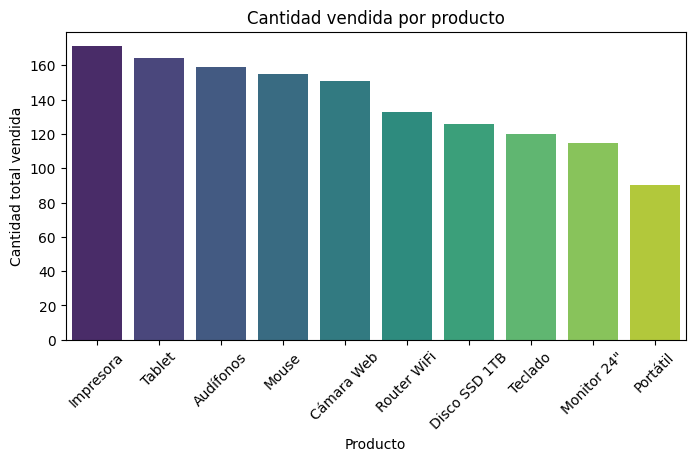

In [140]:
# Agrupar por producto y sumar la cantidad vendida
ventas_producto = df.groupby("nombre")["cantidad"].sum().sort_values(ascending=False)

# Gráfico de barras
plt.figure(figsize=(8,4))
sns.barplot(x=ventas_producto.index, y=ventas_producto.values, hue=ventas_producto.index, palette="viridis")
plt.title("Cantidad vendida por producto")
plt.xlabel("Producto")
plt.ylabel("Cantidad total vendida")
plt.xticks(rotation=45)
plt.show()

**Interpretación:**

* El gráfico presenta cada producto en el eje X y la cantidad total vendida en el eje Y. La barra más alta representa el producto más vendido, mientras que las demás permiten comparar el desempeño relativo de cada uno.
* El gráfico evidencia que la Impresora lidera las ventas superando las 160 unidades vendidas.
* Los productos como Tablet y Audífonos también muestran un desempeño destacado.
* En contraste, artículos como el Portátil y el Monitor 24" tienen menor participación en términos de cantidad pero no es inferior a 80 unidades.
* Esta información es clave para orientar decisiones de inventario, promociones y estrategias comerciales, ya que revela cuáles productos concentran la mayor demanda.

### **Gráfica 2 - Evolución mensual de ventas en 2025**

La segunda visualización corresponde a un gráfico de línea que muestra la evolución del total de ventas a lo largo de los meses del año 2025. Para su construcción, se agruparon los registros por la variable mes y se sumó el valor de la columna total, obteniendo así el ingreso acumulado por cada periodo mensual.

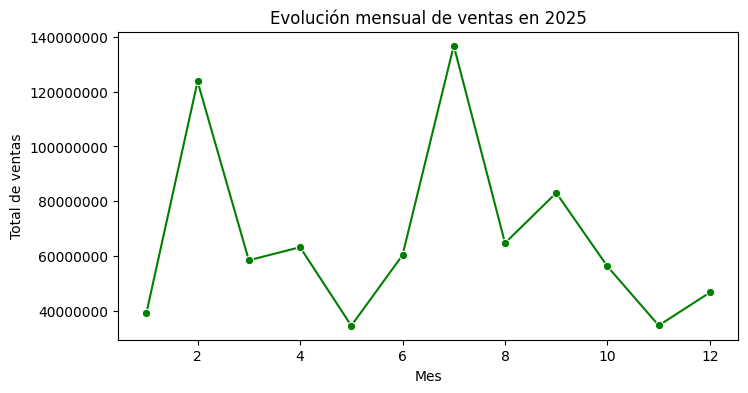

In [141]:
# Agrupar por mes y sumar el total de ventas
ventas_mes = df.groupby("mes")["total"].sum().sort_index()

# Gráfico de línea
plt.figure(figsize=(8,4))
sns.lineplot(x=ventas_mes.index, y=ventas_mes.values, marker="o", color="green")
plt.title("Evolución mensual de ventas en 2025")
plt.xlabel("Mes")
plt.ylabel("Total de ventas")
plt.ticklabel_format(style='plain', axis='y')
plt.show()

**Interpretación:**

* En el eje X se representan los meses (de enero a diciembre) y en el eje Y el total de ventas. Cada punto de la línea indica el valor mensual, y la conexión entre ellos permite observar la tendencia general del comportamiento de las ventas durante el año.
* Se observan picos de ventas en los meses 2 (febrero) y 7 (julio), lo que indica que en esos periodos hubo una mayor actividad comercial.
* En contraste, los meses 5 (mayo) y 11 (noviembre) presentan caídas significativas, reflejando menor demanda o posibles factores externos que afectaron las ventas.
* La variación a lo largo del año sugiere un comportamiento estacional, donde ciertos meses concentran más ventas que otros.
* Esta información es clave para la planificación estratégica: permite anticipar los meses de alta demanda, reforzar inventarios y diseñar campañas de marketing en los periodos de menor actividad.

### **Gráfica 3 - Participación de ventas por canal**

La tercera visualización corresponde a un gráfico circular que muestra la participación porcentual de las ventas según el canal de distribución. Para su construcción, se agruparon los registros por la variable canal y se sumó el valor de la columna total, lo que permite calcular la proporción que cada canal aporta al ingreso global.

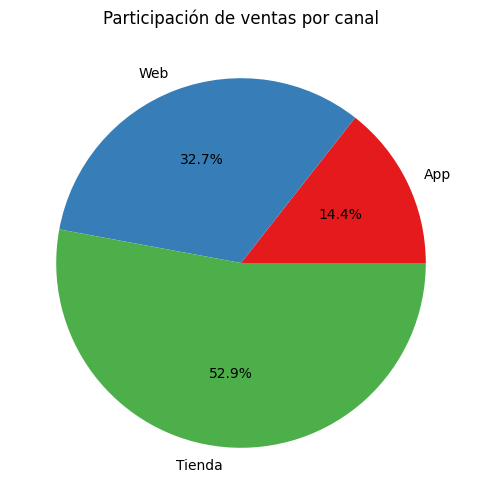

In [142]:
# Agrupar por canal y sumar el total de ventas
ventas_canal = df.groupby("canal")["total"].sum().sort_values()

# Grafico en pie
plt.figure(figsize=(6,6))
plt.pie(ventas_canal.values, labels=ventas_canal.index, autopct="%1.1f%%", colors=sns.color_palette("Set1"))
plt.title("Participación de ventas por canal")
plt.show()

**Interpretación:**

* Cada segmento del gráfico representa un canal, y el porcentaje asociado indica su contribución relativa al total de ventas.
* El canal Tienda concentra más de la mitad de las ventas (52.9%), lo que evidencia que sigue siendo el principal medio de comercialización y el de mayor impacto en los resultados.
* El canal Web aporta alrededor de un tercio (32.7%), mostrando una participación significativa y consolidada en el entorno digital.
* El canal App representa la menor proporción (14.4%), lo que sugiere que aún tiene espacio para crecer y convertirse en un canal más competitivo.
* Esta distribución permite identificar dependencias: la empresa depende fuertemente de las ventas en tienda física, mientras que los canales digitales (Web y App) en conjunto ya representan casi la mitad del total.


### **Gráfica 4 - Ventas totales por ciudad**

La cuarta visualización corresponde a un gráfico de barras que muestra el total de ventas acumuladas en cada ciudad. Para su construcción, se agruparon los registros por la variable ciudad y se sumó el valor de la columna total, ordenando los resultados de mayor a menor.

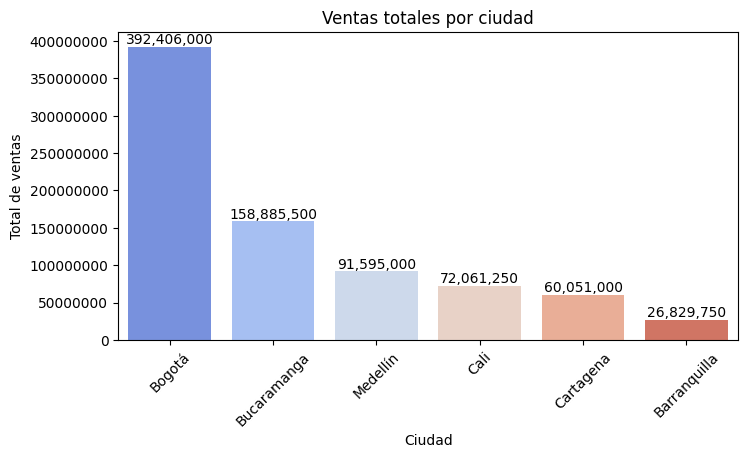

In [143]:
# Agrupar por ciudad y sumar el total de ventas
ventas_ciudad = df.groupby("ciudad")["total"].sum().sort_values(ascending=False)

# Gráfico de barras
plt.figure(figsize=(8,4))
sns.barplot(x=ventas_ciudad.index, y=ventas_ciudad.values, hue=ventas_ciudad.index, palette="coolwarm")
plt.title("Ventas totales por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Total de ventas")
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')

# Agregar etiquetas con el valor exacto encima de cada barra
for i, valor in enumerate(ventas_ciudad.values):
    plt.text(i, valor, f"{int(valor):,}", ha='center', va='bottom')
plt.show()

**Interpretación:**

* En el eje X se representan las ciudades y en el eje Y el total de ventas. Además, se añadieron etiquetas con los valores exactos encima de cada barra, lo que facilita la lectura precisa de los datos y permite comparar rápidamente el desempeño de cada localidad.
* Bogotá se posiciona como la ciudad con mayor volumen de ventas, superando ampliamente a las demás, lo que la convierte en el mercado más relevante para la empresa.
* Bucaramanga ocupa el segundo lugar, con un nivel de ventas considerable, aunque muy por debajo de Bogotá.
* Medellín, Cali y Cartagena presentan valores intermedios, reflejando una participación importante pero menor en comparación con las dos primeras.
* Barranquilla registra el menor total de ventas, lo que evidencia una baja demanda en esa región.
* La diferencia marcada entre Bogotá y el resto de ciudades sugiere una concentración del mercado en la capital, mientras que las demás localidades representan oportunidades de crecimiento y expansión.

## **Gráfica 5 - Boxplots de variables clave**

La quinta visualización corresponde a un conjunto de boxplots que permiten analizar la distribución y detectar valores atípicos en cuatro variables: precio_unitario, subtotal, valor_descuento y total. Cada gráfico resume la información estadística de la variable, mostrando la mediana, los cuartiles y los posibles outliers.

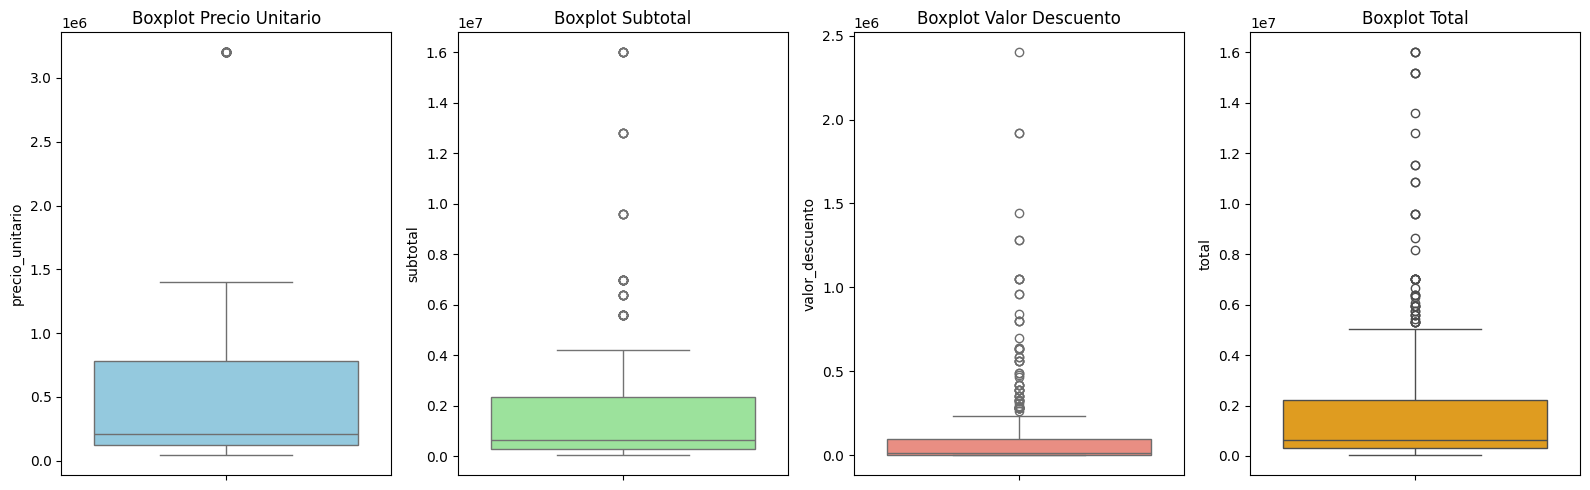

In [144]:
# Boxplots para detectar outliers
fig, axes = plt.subplots(1, 4, figsize=(16,5))
sns.boxplot(y=df["precio_unitario"], ax=axes[0], color="skyblue")
axes[0].set_title("Boxplot Precio Unitario")

sns.boxplot(y=df["subtotal"], ax=axes[1], color="lightgreen")
axes[1].set_title("Boxplot Subtotal")

sns.boxplot(y=df["valor_descuento"], ax=axes[2], color="salmon")
axes[2].set_title("Boxplot Valor Descuento")

sns.boxplot(y=df["total"], ax=axes[3], color="orange")
axes[3].set_title("Boxplot Total")

plt.tight_layout()
plt.show()

**Interpretación:**

* El eje Y representa los valores de cada variable, mientras que la caja central indica el rango intercuartílico (IQR). Los puntos fuera de la caja corresponden a valores extremos que se alejan del comportamiento general.
* Precio unitario: la mayoría de los productos se concentran en un rango bajo, pero existen algunos artículos con precios muy elevados que aparecen como outliers.
* Subtotal: refleja una dispersión amplia, con operaciones pequeñas y otras de gran magnitud. Los valores extremos sugieren ventas de alto volumen.
* Valor descuento: la mayoría de los descuentos son moderados, aunque se observan casos aislados con reducciones muy altas, lo que podría corresponder a promociones especiales o errores de registro.
* Total: la distribución es similar al subtotal, pero ajustada por los descuentos. Los outliers muestran transacciones de gran impacto económico.
* En conjunto, estos boxplots permiten detectar anomalías y comprender la variabilidad de los datos, lo que resulta útil para auditorías, control de calidad y análisis de patrones de consumo.